# 05. Selección del Modelo Ganador, Hold-Out Test, Metas PSet #1 y Model Registry

**Proyecto:** PSet #3 — Experimentación y Selección del Modelo con MLflow  
**Objetivo:** Comparar el ganador (`@champion`) y segundo mejor (`@challenger`) usando promedio y desviación de CV, evaluar ambos **una sola vez** en el conjunto de prueba (*hold-out* `2025-01` a `2026-06`), contrastar las metas macroeconómicas del PSet #1 (`MAPE sectorial`, `WAPE`, `Error de Revisión del IMAEC en pp` e `Índice de Utilidad Relativa`) frente al procedimiento actual (`HeuristicaBCE`), analizar explicabilidad y latencia, registrar ambos en MLflow Model Registry (`nowcasting-f104-modelo`), reproducir exactamente el resultado desde `models:/nowcasting-f104-modelo@champion` y exportar todas las corridas a `docs/corridas.csv`.

In [1]:
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import lightgbm
import xgboost
import catboost
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

load_dotenv(ROOT / ".env", override=False)

from src.datos import (
    dividir_train_test,
    obtener_metadatos_snapshot,
    preparar_universo_nowcasting,
)
from src.pipeline import (
    COLUMNAS_MODELO,
    OBJETIVO,
    HeuristicaBCE,
    agregar_features,
    calcular_error_revision_imaec_pp,
    calcular_mape_sectorial_pct,
    calcular_metricas,
    calcular_utilidad_relativa_pct,
    construir_preparacion,
    evaluar_metas_pset1,
)

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

SEMILLA = 42
NOMBRE_REGISTRO = "nowcasting-f104-modelo"
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENTO = os.environ.get("MLFLOW_EXPERIMENT_NAME", "nowcasting-f104-sri")

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENTO)
client = MlflowClient()
exp = client.get_experiment_by_name(EXPERIMENTO)
meta = obtener_metadatos_snapshot()

universo = preparar_universo_nowcasting()
datos = agregar_features(universo)
train_df, test_df = dividir_train_test(datos)

X_ent = train_df[COLUMNAS_MODELO].copy()
y_ent = train_df[OBJETIVO].astype(float).copy()
X_prueba = test_df[COLUMNAS_MODELO].copy()
y_prueba = test_df[OBJETIVO].astype(float).copy()
print(f"Hold-out test intocable: {len(X_prueba)} filas ({test_df['FECHA_MES'].min().strftime('%Y-%m')} a {test_df['FECHA_MES'].max().strftime('%Y-%m')})")

Hold-out test intocable: 828 filas (2025-01 a 2026-06)


## 1. Comparación CV entre el ganador (#1) y el segundo mejor (#2)

Se recuperan desde MLflow las corridas ajustadas (`fase = 'tuning'`) y candidatas (`fase = 'candidato'`), seleccionando el mejor exponente por clase de modelo para comparar los dos mejores diseños distintos pliegue a pliegue.

In [2]:
all_exp_runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    max_results=5000,
)
runs_comp = (
    all_exp_runs[all_exp_runs["tags.fase"].isin(["tuning", "candidato"])]
    .sort_values("metrics.mae_cv_promedio", ascending=True)
    .reset_index(drop=True)
)
# Mejor corrida por clase de modelo distinta
runs_distintos = runs_comp.drop_duplicates(subset=["tags.modelo_clase"], keep="first").reset_index(drop=True)
top2 = runs_distintos.head(2).copy()

cols_cv_tabla = [
    "tags.mlflow.runName",
    "tags.fase",
    "tags.familia",
    "tags.modelo_clase",
    "metrics.mae_entrenamiento",
    "metrics.mae_cv_promedio",
    "metrics.mae_cv_std",
    "metrics.mae_fold_1",
    "metrics.mae_fold_2",
    "metrics.mae_fold_3",
    "metrics.mae_fold_4",
    "metrics.mae_fold_5",
    "metrics.segundos_entrenamiento",
]
display(top2[cols_cv_tabla].round(4))

ganador_row = top2.iloc[0]
segundo_row = top2.iloc[1]
dif_cv = float(segundo_row["metrics.mae_cv_promedio"] - ganador_row["metrics.mae_cv_promedio"])
std_gan = float(ganador_row["metrics.mae_cv_std"])
print(f"Diferencia CV promedio (#2 - #1): {dif_cv:.4f} M USD | Desviación entre pliegues de #1: {std_gan:.4f} M USD")
print(f"¿La diferencia supera la variación entre pliegues?: {dif_cv > std_gan}")

,tags.mlflow.runName,tags.fase,tags.familia,tags.modelo_clase,metrics.mae_entrenamiento,metrics.mae_cv_promedio,metrics.mae_cv_std,metrics.mae_fold_1,metrics.mae_fold_2,metrics.mae_fold_3,metrics.mae_fold_4,metrics.mae_fold_5,metrics.segundos_entrenamiento
0,tuning_lasso,tuning,lineal_regularizado,Lasso,13.4509,13.9173,1.1121,12.6008,13.0812,13.6043,15.7044,14.5958,0.0419
1,tuning_ridge,tuning,lineal_regularizado,Ridge,13.6540,16.5067,1.8505,15.9762,14.0620,19.3407,17.7653,15.3895,0.0246


Diferencia CV promedio (#2 - #1): 2.5894 M USD | Desviación entre pliegues de #1: 1.1121 M USD
¿La diferencia supera la variación entre pliegues?: True


## 2. Evaluación única en el conjunto de prueba (*hold-out* 2025-01 a 2026-06) y Registro de Modelos

Se cargan los pipelines entrenados en todo `train` desde sus `run_id` de MLflow y se evalúan **una sola vez** sobre `X_prueba, y_prueba`, midiendo métricas técnicas, métricas de negocio, latencia de inferencia y verificando/registrando las versiones en **`nowcasting-f104-modelo`** con los alias **`champion`** y **`challenger`**.

In [3]:
runs_finales_existentes = all_exp_runs[all_exp_runs["tags.fase"] == "final"].copy()
mapa_finales = dict(zip(runs_finales_existentes["tags.mlflow.runName"], runs_finales_existentes["run_id"]))

evaluaciones_finales = []
modelos_cargados = {}
X_ejemplo = X_ent.head(5).copy()

for rol, row in [("champion", ganador_row), ("challenger", segundo_row)]:
    run_src_id = row["run_id"]
    nombre_modelo = row["tags.mlflow.runName"]
    nombre_run_final = f"final_{rol}_{nombre_modelo}"
    familia = row["tags.familia"]
    pipe = mlflow.sklearn.load_model(f"runs:/{run_src_id}/modelo")
    modelos_cargados[rol] = pipe

    # Medir latencia de inferencia promedio (20 repeticiones sobre las 828 filas de test)
    tiempos_ms = []
    for _ in range(20):
        t0 = time.perf_counter()
        pred_test = np.clip(pipe.predict(X_prueba), 0.0, None)
        tiempos_ms.append((time.perf_counter() - t0) * 1000.0)
    ms_lote = float(np.mean(tiempos_ms))
    ms_por_fila = ms_lote / len(X_prueba)

    met_test = calcular_metricas(y_prueba, pred_test)

    if nombre_run_final in mapa_finales:
        run_final_id = mapa_finales[nombre_run_final]
        info_alias = client.get_model_version_by_alias(NOMBRE_REGISTRO, rol)
        version_reg = str(info_alias.version)
    else:
        with mlflow.start_run(run_name=nombre_run_final) as run_fin:
            mlflow.log_params({
                "rol_final": rol,
                "modelo_origen": nombre_modelo,
                "run_id_origen": run_src_id,
                "semilla": SEMILLA,
                "tabla_origen": meta["tabla_origen"],
                "fecha_corte_snapshot": meta["fecha_corte_snapshot"],
                "huella_datos": meta["huella_datos"],
                "filas_entrenamiento": len(X_ent),
                "filas_prueba_holdout": len(X_prueba),
                "periodo_holdout": "2025-01 a 2026-06",
            })
            mlflow.log_metrics({
                "mae_cv_promedio": float(row["metrics.mae_cv_promedio"]),
                "mae_cv_std": float(row["metrics.mae_cv_std"]),
                "mae_prueba": met_test["mae"],
                "rmse_prueba": met_test["rmse"],
                "r2_prueba": met_test["r2"],
                "wape_prueba_pct": met_test["wape_pct"],
                "costo_negocio_prueba_musd": met_test["costo_negocio_musd"],
                "segundos_entrenamiento": float(row["metrics.segundos_entrenamiento"]),
                "inferencia_lote_ms": ms_lote,
                "inferencia_fila_ms": ms_por_fila,
            })
            mlflow.set_tags({
                "fase": "final",
                "candidato": "final" if rol == "champion" else "segundo_mejor",
                "rol_registro": rol,
                "familia": familia,
                "git_commit": meta["git_commit"],
                "modelo_clase": row["tags.modelo_clase"],
            })
            sig = infer_signature(X_ejemplo, np.clip(pipe.predict(X_ejemplo), 0.0, None))
            model_info = mlflow.sklearn.log_model(
                pipe,
                artifact_path="modelo",
                signature=sig,
                input_example=X_ejemplo,
                registered_model_name=NOMBRE_REGISTRO,
            )
            version_reg = str(model_info.registered_model_version)
            client.set_registered_model_alias(NOMBRE_REGISTRO, rol, version_reg)
            run_final_id = run_fin.info.run_id

    evaluaciones_finales.append({
        "rol": rol,
        "modelo": nombre_modelo,
        "clase": row["tags.modelo_clase"],
        "run_id_final": run_final_id,
        "version_registro": version_reg,
        "mae_cv": round(float(row["metrics.mae_cv_promedio"]), 4),
        "std_cv": round(float(row["metrics.mae_cv_std"]), 4),
        "mae_prueba": round(met_test["mae"], 4),
        "rmse_prueba": round(met_test["rmse"], 4),
        "r2_prueba": round(met_test["r2"], 4),
        "wape_prueba_pct": round(met_test["wape_pct"], 3),
        "costo_negocio_prueba_musd": round(met_test["costo_negocio_musd"], 4),
        "entrenamiento_s": round(float(row["metrics.segundos_entrenamiento"]), 3),
        "inferencia_828filas_ms": round(ms_lote, 3),
        "predicciones": pred_test,
    })

df_final = pd.DataFrame([{k: v for k, v in d.items() if k != "predicciones"} for d in evaluaciones_finales])
display(df_final)

,rol,modelo,clase,run_id_final,version_registro,mae_cv,std_cv,mae_prueba,rmse_prueba,r2_prueba,wape_prueba_pct,costo_negocio_prueba_musd,entrenamiento_s,inferencia_828filas_ms
0,champion,tuning_lasso,Lasso,b4bd242a500b42eea087a6cc9918097a,1,13.9173,1.1121,14.7905,27.1961,0.9995,3.267,18.6305,0.042,2.442
1,challenger,tuning_ridge,Ridge,2ae1ddac80d24c5d92acc83b3f4f6b01,2,16.5067,1.8505,17.0578,33.9354,0.9992,3.767,22.3703,0.025,2.400


## 3. Evaluación de Metas del PSet #1: VAB del IMAEC, Error de Revisión (pp), MAPE Sectorial e Índice de Utilidad Relativa

Para responder integralmente a las **Observaciones 2 y 4 del PSet #1**, se contrasta el desempeño de la línea base operativa vigente del BCE (`HeuristicaBCE`), del retador (`@challenger`: `tuning_ridge`) y del modelo campeón (`@champion`: `tuning_lasso`) tanto en **Validación Cruzada Temporal (5 pliegues, 2017-07 a 2024-12)** como en el **Conjunto de Prueba Hold-Out (2025-01 a 2026-06, 828 observaciones)**:

- **Transformación Ventas F104 $\to$ VAB del IMAEC:** bajo coeficientes técnicos fijos de corto plazo ($\Delta\% \text{VAB}_{i,t} \approx \Delta\% V_{i,t}^{\text{real}}$), la tasa de variación interanual del agregado de las 46 ramas al día 15 ($\widehat{g}_t^{(15\text{d})}$) aproxima directamente la señal adelantada del IMAEC Flash frente al cierre definitivo ($\text{ER}_t = |\widehat{g}_t^{(15\text{d})} - g_t^{(\text{def})}|$, expresado en **puntos porcentuales `pp`**).
- **Índice de Utilidad Relativa frente al Procedimiento Actual (`utilidad_relativa_vs_bce_pct`):** mide la reducción porcentual del costo de revisión asimétrico respecto a `HeuristicaBCE`.

In [4]:
# 3.1 Reconstrucción de predicciones out-of-fold en CV para HeuristicaBCE, Challenger y Champion
meses_unicos = np.sort(train_df["FECHA_MES"].unique())
cv_temporal = [
    (
        np.where(train_df["FECHA_MES"].isin(meses_unicos[m_tr]))[0],
        np.where(train_df["FECHA_MES"].isin(meses_unicos[m_val]))[0],
    )
    for m_tr, m_val in TimeSeriesSplit(n_splits=5).split(meses_unicos)
]

modelos_comparar = [
    ("HeuristicaBCE (Procedimiento Actual)", Pipeline([("m", HeuristicaBCE())])),
    ("tuning_ridge (@challenger v2)", modelos_cargados["challenger"]),
    ("tuning_lasso (@champion v1)", modelos_cargados["champion"]),
]

oof_preds = {nombre: [] for nombre, _ in modelos_comparar}
cv_folds_summary = {nombre: [] for nombre, _ in modelos_comparar}

for tr_i, val_i in cv_temporal:
    for nombre, pipe_base in modelos_comparar:
        p_clone = clone(pipe_base)
        p_clone.fit(X_ent.iloc[tr_i], y_ent.iloc[tr_i])
        pred_v = np.clip(p_clone.predict(X_ent.iloc[val_i]), 0.0, None)
        m_v = calcular_metricas(y_ent.iloc[val_i], pred_v)
        m_v["mape_sectorial_pct"] = calcular_mape_sectorial_pct(y_ent.iloc[val_i], pred_v)
        cv_folds_summary[nombre].append(m_v)
        sub_df = train_df.iloc[val_i][["FECHA_MES", "CODIGO_INDUSTRIA", OBJETIVO, "ventas_definitivo_real_lag12_musd"]].copy()
        sub_df["pred"] = pred_v
        oof_preds[nombre].append(sub_df)

df_oof_bce = pd.concat(oof_preds["HeuristicaBCE (Procedimiento Actual)"], ignore_index=True)
costo_bce_cv_mean = float(pd.DataFrame(cv_folds_summary["HeuristicaBCE (Procedimiento Actual)"])["costo_negocio_musd"].mean())

filas_metas = []
# Resumen en CV (5 pliegues)
for nombre, _ in modelos_comparar:
    df_m = pd.DataFrame(cv_folds_summary[nombre])
    df_o = pd.concat(oof_preds[nombre], ignore_index=True)
    er_o = calcular_error_revision_imaec_pp(df_o, df_o[OBJETIVO], df_o["pred"])
    costo_m = float(df_m["costo_negocio_musd"].mean())
    iup_cv = (1.0 - costo_m / costo_bce_cv_mean) * 100.0
    filas_metas.append({
        "Partición": "CV Temporal (5 pliegues)",
        "Modelo": nombre,
        "MAE (M USD)": round(float(df_m["mae"].mean()), 4),
        "RMSE (M USD)": round(float(df_m["rmse"].mean()), 4),
        "WAPE (%)": round(float(df_m["wape_pct"].mean()), 3),
        "MAPE Sectorial (%)": round(float(df_m["mape_sectorial_pct"].mean()), 2),
        "WAPE Agregado IMAEC (%)": round(er_o["wape_agregado_imaec_pct"], 3),
        "Error Revisión IMAEC Medio (pp)": round(er_o["error_revision_imaec_pp"], 3),
        "Error Revisión IMAEC Mediana (pp)": round(er_o["error_revision_mediana_pp"], 3),
        "Costo Negocio (M USD)": round(costo_m, 4),
        "Utilidad vs. BCE (IUP %)": round(iup_cv, 2),
    })

# Resumen en Hold-Out Test (2025-01 a 2026-06, 828 filas)
pred_test_bce = np.clip(HeuristicaBCE().fit(X_ent, y_ent).predict(X_prueba), 0.0, None)
preds_test_map = {
    "HeuristicaBCE (Procedimiento Actual)": pred_test_bce,
    "tuning_ridge (@challenger v2)": evaluaciones_finales[1]["predicciones"],
    "tuning_lasso (@champion v1)": evaluaciones_finales[0]["predicciones"],
}

for nombre, pred_t in preds_test_map.items():
    res_t = evaluar_metas_pset1(test_df, y_prueba, pred_t, y_pred_baseline_bce=pred_test_bce)
    filas_metas.append({
        "Partición": "Hold-Out Test (2025-01..2026-06)",
        "Modelo": nombre,
        "MAE (M USD)": round(res_t["mae"], 4),
        "RMSE (M USD)": round(res_t["rmse"], 4),
        "WAPE (%)": round(res_t["wape_pct"], 3),
        "MAPE Sectorial (%)": round(res_t["mape_sectorial_pct"], 2),
        "WAPE Agregado IMAEC (%)": round(res_t["wape_agregado_imaec_pct"], 3),
        "Error Revisión IMAEC Medio (pp)": round(res_t["error_revision_imaec_pp"], 3),
        "Error Revisión IMAEC Mediana (pp)": round(res_t["error_revision_mediana_pp"], 3),
        "Costo Negocio (M USD)": round(res_t["costo_negocio_musd"], 4),
        "Utilidad vs. BCE (IUP %)": round(res_t["utilidad_relativa_vs_bce_pct"], 2),
    })

df_metas_pset1 = pd.DataFrame(filas_metas)
display(df_metas_pset1)

,Partición,Modelo,MAE (M USD),RMSE (M USD),WAPE (%),MAPE Sectorial (%),WAPE Agregado IMAEC (%),Error Revisión IMAEC Medio (pp),Error Revisión IMAEC Mediana (pp),Costo Negocio (M USD),Utilidad vs. BCE (IUP %)
0,CV Temporal (5 pliegues),HeuristicaBCE (Procedimiento Actual),13.8037,27.3903,3.771,15.29,0.783,0.800,0.620,17.4182,0.00
1,CV Temporal (5 pliegues),tuning_ridge (@challenger v2),16.5067,31.4794,4.541,28.88,1.331,1.439,0.965,20.6975,-18.83
2,CV Temporal (5 pliegues),tuning_lasso (@champion v1),13.9173,28.8548,3.812,18.05,1.131,1.220,0.927,16.9270,2.82
3,Hold-Out Test (2025-01..2026-06),HeuristicaBCE (Procedimiento Actual),15.4340,28.6713,3.409,6.60,0.725,0.781,0.688,19.8506,0.00
4,Hold-Out Test (2025-01..2026-06),tuning_ridge (@challenger v2),17.0578,33.9354,3.767,11.35,1.070,1.178,1.203,22.3703,-12.69
5,Hold-Out Test (2025-01..2026-06),tuning_lasso (@champion v1),14.7905,27.1961,3.267,8.54,0.571,0.614,0.424,18.6305,6.15


## 4. Explicabilidad, desempeño agregado del IMAEC Flash y análisis de residuos

Se evalúa la importancia por permutación sobre las 22 variables de entrada de negocio en el *hold-out*, el seguimiento mensual de las ventas reales agregadas de las 46 ramas (equivalente al nivel del IMAEC Flash) y la distribución de errores por macro-sector.

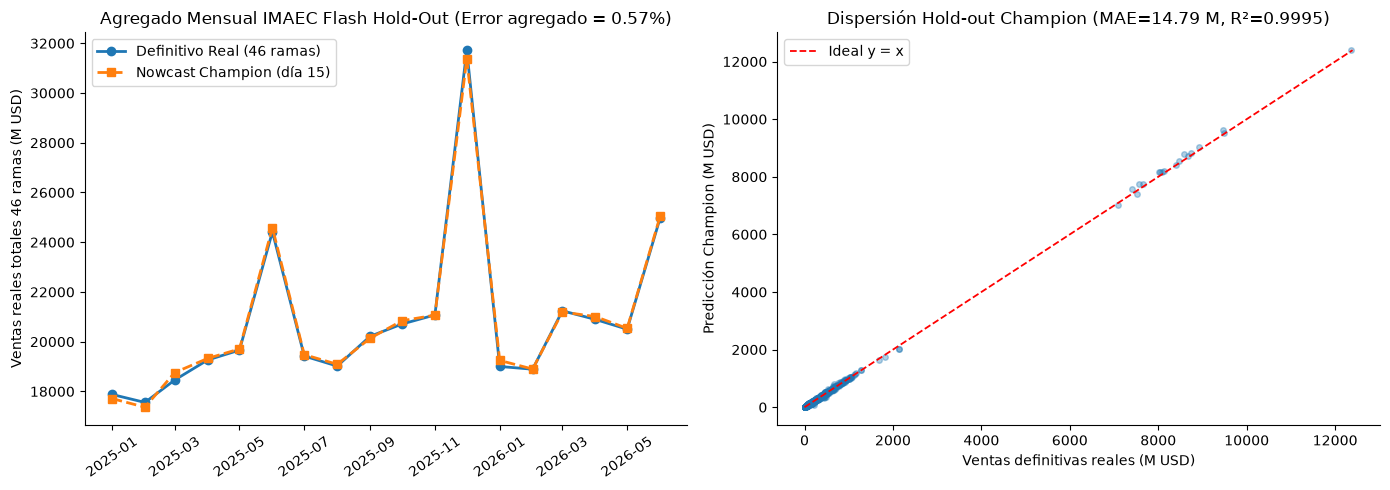

,variable,importancia_mae_musd,std
6,proyeccion_cobertura_12m,561.3966,12.0198
12,ventas_definitivo_real_lag12_musd,12.2113,0.5188
7,ratio_temprano_vs_lag12,0.2318,0.0379
8,ratio_temprano_vs_lag1,0.0420,0.0260
1,NUM_DECLARANTES,0.0000,0.0000
2,ventas_temprano_por_declarante_real,0.0000,0.0000
14,CODIGO_INDUSTRIA,0.0000,0.0000
5,RATIO_REPRESENTATIVIDAD_HIST_12M,0.0000,0.0000
3,INDICE_PRECIO_REAL,0.0000,0.0000
4,inflacion_sectorial_12m_lag1,0.0000,0.0000


,obs,venta_media_musd,mae_musd
SECTOR_MACRO,,,
Comercio,18,8477.71,103.59
Construccion,18,466.10,21.21
Servicios sociales y administracion publica,54,247.46,21.14
Petroleo y minas,36,253.83,18.28
Electricidad y agua,18,483.26,17.68
Servicios empresariales y otros servicios,144,506.36,15.86
Manufactura,414,186.99,10.77
"Agricultura, ganaderia, silvicultura y pesca",126,257.11,9.05


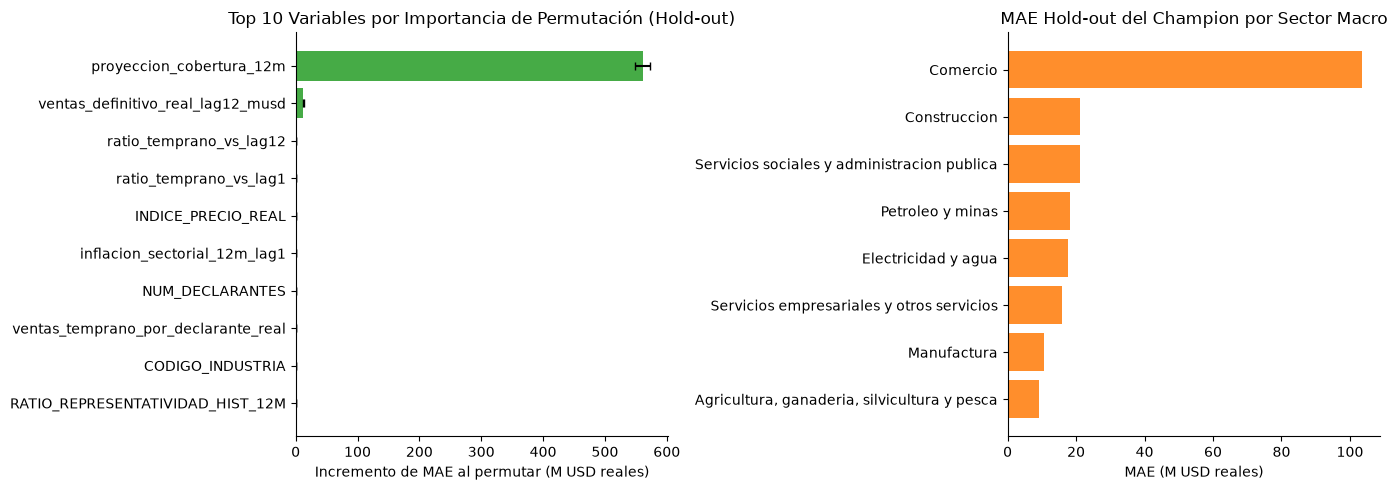

In [5]:
pipe_champ = modelos_cargados["champion"]
pred_champ = evaluaciones_finales[0]["predicciones"]

# Gráfico 1: Hold-out predicción vs real por rama-mes y seguimiento agregado mensual (IMAEC)
eval_df = test_df[["FECHA_MES", "CODIGO_INDUSTRIA", "SECTOR_MACRO"]].copy()
eval_df["real_musd"] = y_prueba.values
eval_df["pred_musd"] = pred_champ
eval_df["error_abs"] = np.abs(eval_df["real_musd"] - eval_df["pred_musd"])

mensual_agg = eval_df.groupby("FECHA_MES")[["real_musd", "pred_musd"]].sum().reset_index()
wape_agg = np.abs(mensual_agg["real_musd"] - mensual_agg["pred_musd"]).sum() / mensual_agg["real_musd"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(mensual_agg["FECHA_MES"], mensual_agg["real_musd"], marker="o", lw=2, label="Definitivo Real (46 ramas)")
axes[0].plot(mensual_agg["FECHA_MES"], mensual_agg["pred_musd"], marker="s", lw=2, linestyle="--", label="Nowcast Champion (día 15)")
axes[0].set_title(f"Agregado Mensual IMAEC Flash Hold-Out (Error agregado = {wape_agg:.2f}%)")
axes[0].set_ylabel("Ventas reales totales 46 ramas (M USD)")
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend()

axes[1].scatter(eval_df["real_musd"], eval_df["pred_musd"], alpha=0.35, s=16, color="#1f77b4")
max_lim = max(eval_df["real_musd"].max(), eval_df["pred_musd"].max())
axes[1].plot([0, max_lim], [0, max_lim], "r--", lw=1.3, label="Ideal y = x")
axes[1].set_title(f"Dispersión Hold-out Champion (MAE={evaluaciones_finales[0]['mae_prueba']:.2f} M, R²={evaluaciones_finales[0]['r2_prueba']:.4f})")
axes[1].set_xlabel("Ventas definitivas reales (M USD)")
axes[1].set_ylabel("Predicción Champion (M USD)")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "05_evaluacion_holdout.png", dpi=180, bbox_inches="tight")
plt.show()

# Explicabilidad: Importancia por permutación (neg_mean_absolute_error) sobre hold-out
perm = permutation_importance(
    pipe_champ,
    X_prueba,
    y_prueba,
    n_repeats=10,
    random_state=SEMILLA,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
imp_df = pd.DataFrame({
    "variable": COLUMNAS_MODELO,
    "importancia_mae_musd": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("importancia_mae_musd", ascending=False)
display(imp_df.head(12).round(4))

err_sector = (
    eval_df.groupby("SECTOR_MACRO")
    .agg(
        obs=("real_musd", "count"),
        venta_media_musd=("real_musd", "mean"),
        mae_musd=("error_abs", "mean"),
    )
    .sort_values("mae_musd", ascending=False)
    .round(2)
)
display(err_sector)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_imp = imp_df.head(10).sort_values("importancia_mae_musd", ascending=True)
axes[0].barh(top_imp["variable"], top_imp["importancia_mae_musd"], xerr=top_imp["std"], color="#2ca02c", alpha=0.88, capsize=3)
axes[0].set_title("Top 10 Variables por Importancia de Permutación (Hold-out)")
axes[0].set_xlabel("Incremento de MAE al permutar (M USD reales)")

err_plot = err_sector.sort_values("mae_musd", ascending=True)
axes[1].barh(err_plot.index, err_plot["mae_musd"], color="#ff7f0e", alpha=0.88)
axes[1].set_title("MAE Hold-out del Champion por Sector Macro")
axes[1].set_xlabel("MAE (M USD reales)")

plt.tight_layout()
fig.savefig(FIG_DIR / "05_explicabilidad_champion.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Reproducibilidad desde el Model Registry y exportación de `docs/corridas.csv`

Se carga el modelo campeón directamente mediante su URI de registro `models:/nowcasting-f104-modelo@champion`, se verifica que reproduce exactamente la métrica registrada en prueba (diferencia `0.0`), y se exporta la bitácora completa de corridas con `mlflow.search_runs`.

In [6]:
uri_champion = f"models:/{NOMBRE_REGISTRO}@champion"
modelo_reproducido = mlflow.sklearn.load_model(uri_champion)
pred_repro = np.clip(modelo_reproducido.predict(X_prueba), 0.0, None)
mae_reproducido = calcular_metricas(y_prueba, pred_repro)["mae"]
mae_registrado = evaluaciones_finales[0]["mae_prueba"]

dif_repro = abs(mae_reproducido - float(calcular_metricas(y_prueba, pred_champ)["mae"]))
assert dif_repro < 1e-9, f"Discrepancia al reproducir desde el registro: {dif_repro}"

info_champ = client.get_model_version_by_alias(NOMBRE_REGISTRO, "champion")
info_chall = client.get_model_version_by_alias(NOMBRE_REGISTRO, "challenger")

print(f"[OK] Reproducibilidad verificada desde {uri_champion}:")
print(f"     Champion  -> versión {info_champ.version} | run_id {info_champ.run_id} | MAE prueba = {mae_reproducido:.6f} (dif = {dif_repro:.2e})")
print(f"     Challenger-> versión {info_chall.version} | run_id {info_chall.run_id} | MAE prueba = {evaluaciones_finales[1]['mae_prueba']:.6f}")

corridas_export = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    order_by=["start_time ASC"],
)
ruta_csv = ROOT / "docs" / "corridas.csv"
ruta_csv.parent.mkdir(parents=True, exist_ok=True)
corridas_export.to_csv(ruta_csv, index=False)

print(f"\nExportado {ruta_csv}: {len(corridas_export)} corridas registradas en total.")
print("Conteo de corridas por fase:")
print(corridas_export["tags.fase"].value_counts().to_string())

[OK] Reproducibilidad verificada desde models:/nowcasting-f104-modelo@champion:
     Champion  -> versión 1 | run_id b4bd242a500b42eea087a6cc9918097a | MAE prueba = 14.790546 (dif = 0.00e+00)
     Challenger-> versión 2 | run_id 2ae1ddac80d24c5d92acc83b3f4f6b01 | MAE prueba = 17.057800

Exportado D:\Maestria Ciencia de Datos\asignatures\3_data_science\3_1_homeworks\pset_3\docs\corridas.csv: 105 corridas registradas en total.
Conteo de corridas por fase:
tags.fase
tuning_trial    90
candidato        8
tuning           3
baseline         2
final            2
